In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('viridis')
os.makedirs('./reports/figures', exist_ok=True)

In [2]:
#1. Load Data
df = pd.read_csv('./data/raw/finguard-fraud-detection-dataset.csv')
print(f"Shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")
print(df.head())

#2. Basic Info
print("\n=== Data Info ===")
df.info()
print("\n=== Missing Values ===")
print(df.isnull().sum().sum())
print("\n=== Duplicate Rows ===")
print(df.duplicated().sum())

Shape: (6362620, 11)
Columns: ['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']
   step      type    amount     nameOrig  oldbalanceOrg  newbalanceOrig  \
0     1   PAYMENT   9839.64  C1231006815       170136.0       160296.36   
1     1   PAYMENT   1864.28  C1666544295        21249.0        19384.72   
2     1  TRANSFER    181.00  C1305486145          181.0            0.00   
3     1  CASH_OUT    181.00   C840083671          181.0            0.00   
4     1   PAYMENT  11668.14  C2048537720        41554.0        29885.86   

      nameDest  oldbalanceDest  newbalanceDest  isFraud  isFlaggedFraud  
0  M1979787155             0.0             0.0        0               0  
1  M2044282225             0.0             0.0        0               0  
2   C553264065             0.0             0.0        1               0  
3    C38997010         21182.0             0.0        1               0 

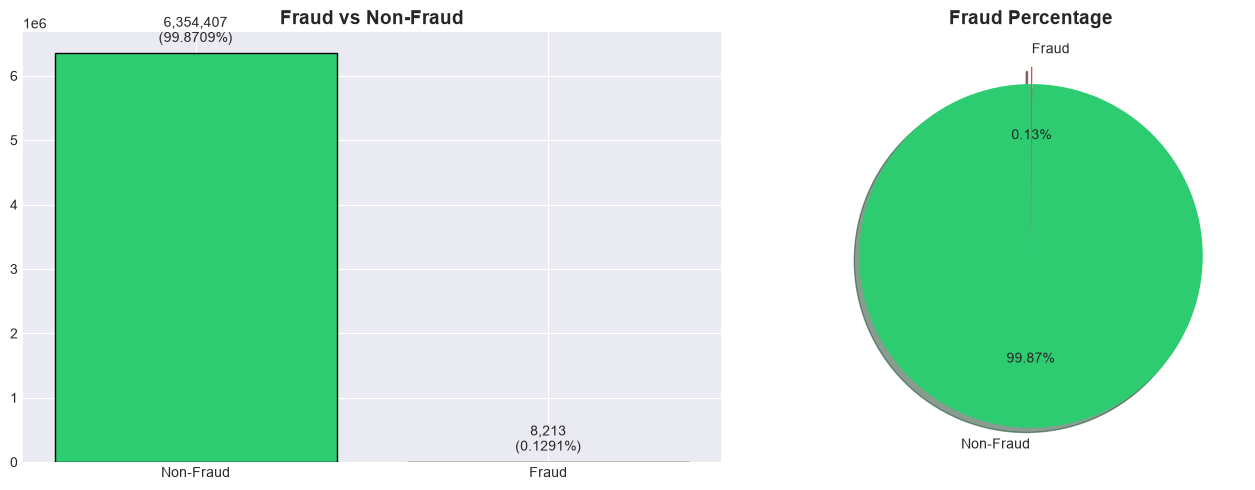

In [3]:
#3. Target Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fraud_counts = df['isFraud'].value_counts()
bars = axes[0].bar(['Non-Fraud', 'Fraud'], fraud_counts.values,
                   color=['#2ecc71', '#e74c3c'], edgecolor='black')
axes[0].set_title('Fraud vs Non-Fraud', fontsize=14, fontweight='bold')
total = len(df)
for bar in bars:
    h = bar.get_height()
    axes[0].annotate(f'{h:,}\n({100*h/total:.4f}%)',
                     xy=(bar.get_x() + bar.get_width()/2, h),
                     xytext=(0, 5), textcoords="offset points",
                     ha='center', va='bottom')

axes[1].pie(fraud_counts.values, labels=['Non-Fraud', 'Fraud'],
            autopct='%1.2f%%', colors=['#2ecc71', '#e74c3c'],
            explode=(0.05, 0.05), shadow=True, startangle=90)
axes[1].set_title('Fraud Percentage', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('./reports/figures/fraud_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


=== Fraud by Transaction Type ===
          Fraud_Count    Total  Fraud_Rate
type                                      
CASH_OUT         4116  2237500    0.183955
TRANSFER         4097   532909    0.768799
CASH_IN             0  1399284    0.000000
DEBIT               0    41432    0.000000
PAYMENT             0  2151495    0.000000


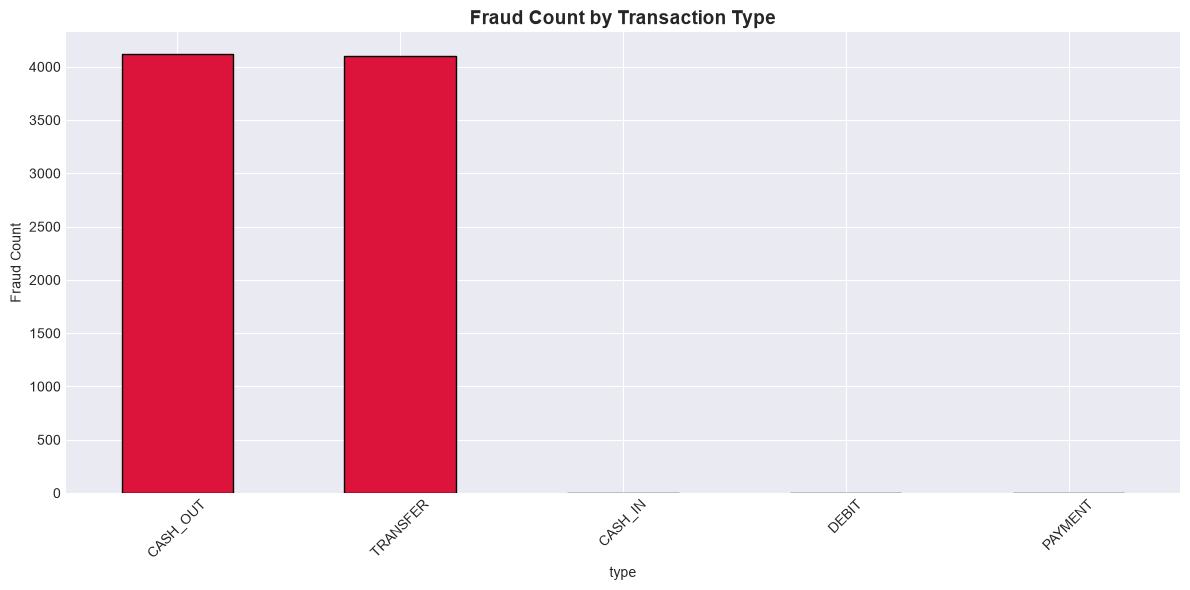

In [4]:
#4. Transaction Type vs Fraud
print("\n=== Fraud by Transaction Type ===")
type_stats = df.groupby('type')['isFraud'].agg(['sum', 'count', 'mean'])
type_stats.columns = ['Fraud_Count', 'Total', 'Fraud_Rate']
type_stats['Fraud_Rate'] = type_stats['Fraud_Rate'] * 100
type_stats = type_stats.sort_values('Fraud_Count', ascending=False)
print(type_stats)

fig, ax = plt.subplots(figsize=(12, 6))
type_stats['Fraud_Count'].plot(kind='bar', ax=ax, color='crimson', edgecolor='black')
ax.set_title('Fraud Count by Transaction Type', fontsize=14, fontweight='bold')
ax.set_ylabel('Fraud Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=45)
plt.tight_layout()
plt.savefig('./reports/figures/transaction_type_fraud.png', dpi=300, bbox_inches='tight')
plt.show()

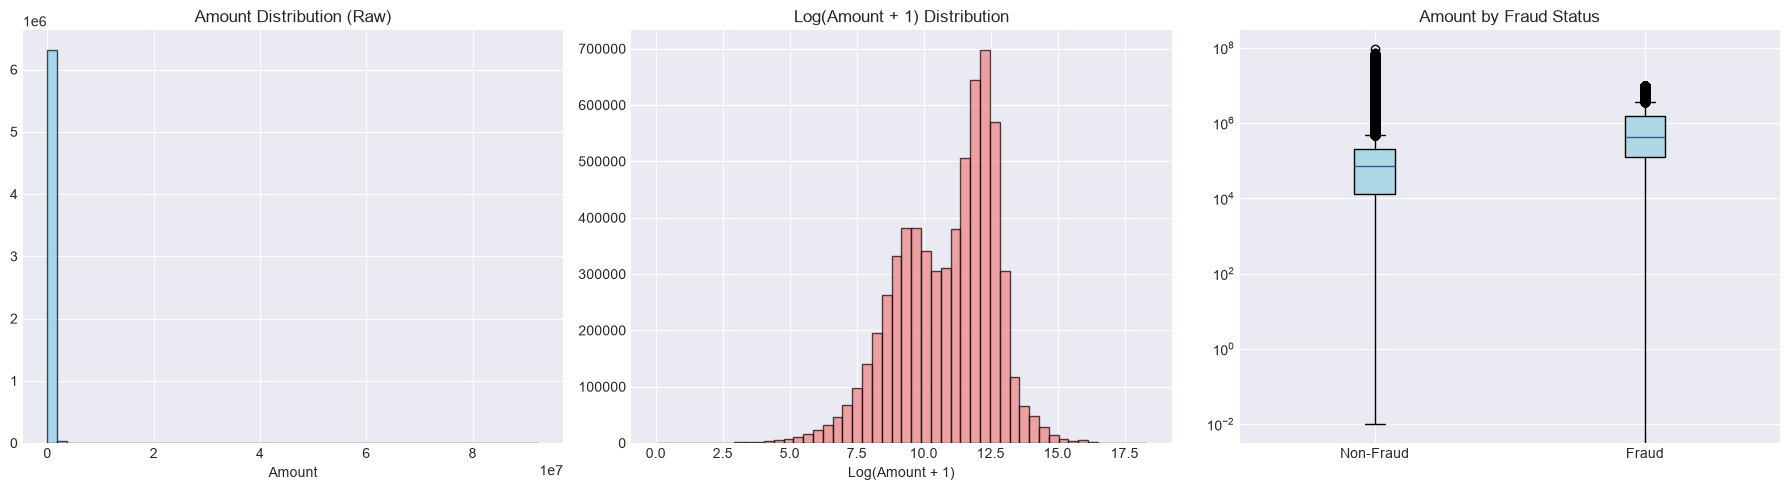


=== Amount Statistics by Fraud ===
             count        mean         std   min        25%        50%  \
isFraud                                                                  
0        6354407.0   178197.04   596236.98  0.01   13368.40   74684.72   
1           8213.0  1467967.30  2404252.95  0.00  127091.33  441423.44   

                75%          max  
isFraud                           
0         208364.76  92445516.64  
1        1517771.48  10000000.00  


In [5]:
#5. Amount Analysis
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(df['amount'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0].set_title('Amount Distribution (Raw)')
axes[0].set_xlabel('Amount')

axes[1].hist(np.log1p(df['amount']), bins=50, color='lightcoral',
             edgecolor='black', alpha=0.7)
axes[1].set_title('Log(Amount + 1) Distribution')
axes[1].set_xlabel('Log(Amount + 1)')

fraud_amt = df[df['isFraud']==1]['amount']
nonfraud_amt = df[df['isFraud']==0]['amount']
axes[2].boxplot([nonfraud_amt, fraud_amt], tick_labels=['Non-Fraud', 'Fraud'],
                patch_artist=True, boxprops=dict(facecolor='lightblue'))
axes[2].set_title('Amount by Fraud Status')
axes[2].set_yscale('log')

plt.tight_layout()
plt.savefig('./reports/figures/amount_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n=== Amount Statistics by Fraud ===")
print(df.groupby('isFraud')['amount'].describe().round(2))

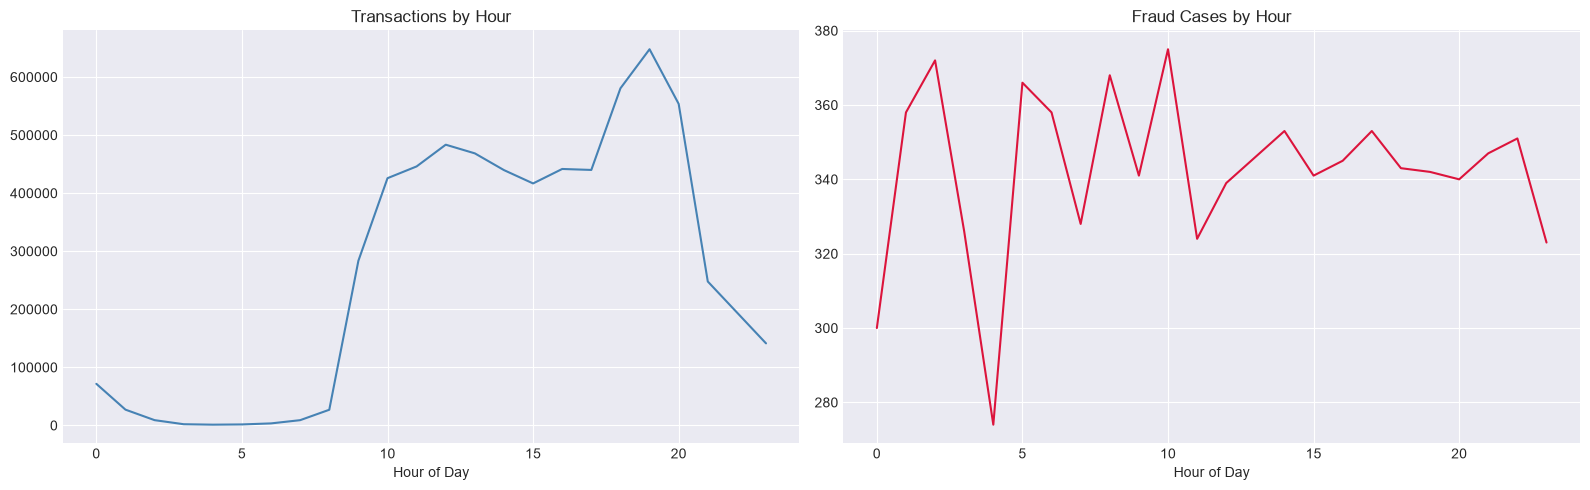

In [6]:
#6. Time Analysis
df['hour'] = df['step'] % 24
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
df.groupby('hour').size().plot(ax=axes[0], color='steelblue')
axes[0].set_title('Transactions by Hour')
axes[0].set_xlabel('Hour of Day')

df[df['isFraud']==1].groupby('hour').size().plot(ax=axes[1], color='crimson')
axes[1].set_title('Fraud Cases by Hour')
axes[1].set_xlabel('Hour of Day')

plt.tight_layout()
plt.savefig('./reports/figures/time_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

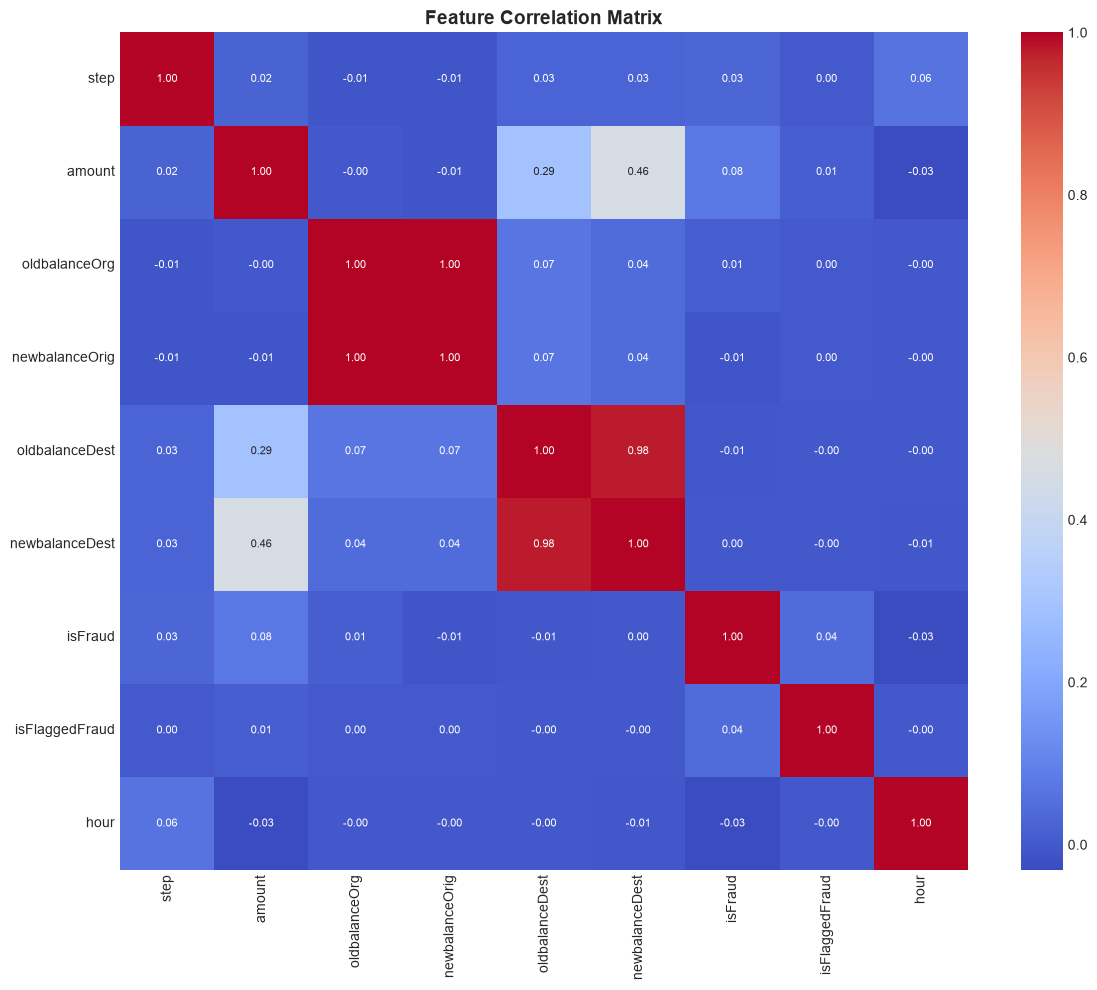

In [7]:
#7. Correlation Matrix
numeric_df = df.select_dtypes(include=[np.number])
fig, ax = plt.subplots(figsize=(12, 10))
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax,
            annot_kws={'size': 8}, cbar=True)
ax.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('./reports/figures/correlation_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
#8. Rule-Based Baseline
print("\n=== isFlaggedFraud Baseline ===")
flagged = df['isFlaggedFraud'].sum()
total_fraud = df['isFraud'].sum()
detected = df[(df['isFraud']==1) & (df['isFlaggedFraud']==1)].shape[0]
missed = total_fraud - detected
false_pos = df[(df['isFraud']==0) & (df['isFlaggedFraud']==1)].shape[0]

print(f"Total Flagged:    {flagged}")
print(f"Actual Frauds:    {total_fraud:,}")
print(f"Detected:         {detected} ({detected/total_fraud*100:.2f}%)")
print(f"Missed:           {missed:,}")
print(f"False Positives:  {false_pos}")


=== isFlaggedFraud Baseline ===
Total Flagged:    16
Actual Frauds:    8,213
Detected:         16 (0.19%)
Missed:           8,197
False Positives:  0


In [9]:
#9. Summary
print("\n" + "="*60)
print("EDA SUMMARY")
print("="*60)
print(f"Total Transactions:    {len(df):,}")
print(f"Fraud Cases:           {total_fraud:,} ({total_fraud/len(df)*100:.4f}%)")
print(f"Imbalance Ratio:       1:{int((len(df)-total_fraud)/total_fraud)}")
print(f"Most Fraud-Prone Type: CASH_OUT & TRANSFER")
print(f"Rule-based Catch Rate: {detected/total_fraud*100:.2f}% (very poor)")


EDA SUMMARY
Total Transactions:    6,362,620
Fraud Cases:           8,213 (0.1291%)
Imbalance Ratio:       1:773
Most Fraud-Prone Type: CASH_OUT & TRANSFER
Rule-based Catch Rate: 0.19% (very poor)
